# 01 — Simple Baseline Model (Fractional Logistic Regression)

A clean starting model for the 2016 UK EU Referendum vote share:
1. **Load Data:** `brexitevote-ep2017.dta` ($n = 380$ Great Britain Local Authority Districts).
2. **Explore:** Spread of Leave vote share across the 11 UK macro-regions.
3. **Fit Fractional Logistic Regression:** Model the continuous Leave proportion $p_i \in (0, 1)$ from **5 core socio-demographic features** using a Binomial GLM with logit link (Papke & Wooldridge, 1996) and check 10-fold CV RMSE.
4. **Plot:** Actual vs. Predicted Leave vote share.
5. **Diagram:** Fitted logistic S-curve across all 380 districts.

## 1. Load Data

In [8]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent 
df = pd.read_stata(ROOT / "data" / "raw" / "brexitevote-ep2017.dta")
df = df[df["Pct_Leave"].notna()].rename(columns={"code": "Area_Code"}).reset_index(drop=True)

print(f"Loaded {len(df)} GB Local Authority Districts")
df[["Area_Code", "Area", "Region", "Pct_Leave"]].head()

Loaded 380 GB Local Authority Districts


,Area_Code,Area,Region,Pct_Leave
0,E06000001,Hartlepool,North East,69.57
1,E06000002,Middlesbrough,North East,65.48
2,E06000003,Redcar and Cleveland,North East,66.19
3,E06000004,Stockton-on-Tees,North East,61.73
4,E06000005,Darlington,North East,56.18


In [9]:
# Ensure 380 area codes loaded
assert len(df) == 380

### Interactive table viewer for Brexit outcome and covariates by area

In [10]:
from IPython.display import HTML, display
from itables import init_notebook_mode, show

init_notebook_mode(all_interactive=False)

display(HTML("""
<style>
.dt-container, .dt-container table, .dt-container th, .dt-container td {
    color: #e6e6e6 !important;
    background-color: #1e1e1e !important;
    border-color: #3c3c3c !important;
}
.dt-container input, .dt-container select {
    color: #e6e6e6 !important;
    background-color: #2d2d2d !important;
    border: 1px solid #555 !important;
}
</style>
"""))

show(df)

## 2. Spread of Leave Votes Across Regions

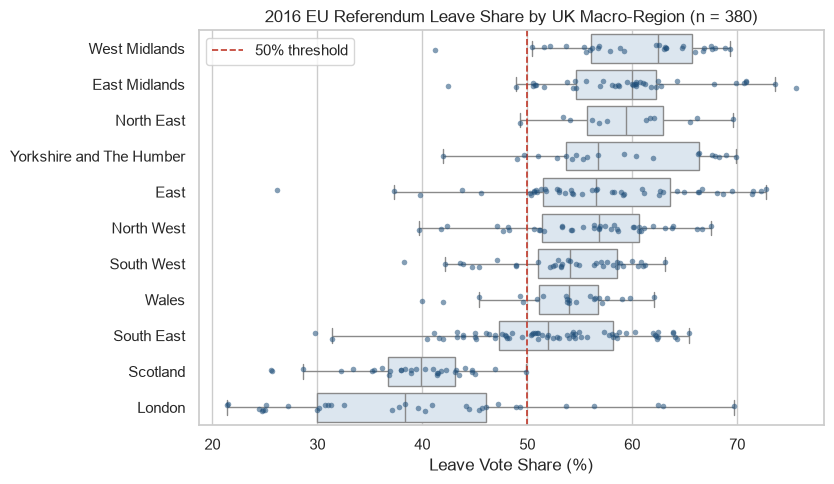

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
order = df.groupby("Region")["Pct_Leave"].mean().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(8.5, 5))
sns.boxplot(data=df, y="Region", x="Pct_Leave", order=order, color="#d9e6f2", fliersize=0, ax=ax)
sns.stripplot(data=df, y="Region", x="Pct_Leave", order=order, color="#1f4e79", alpha=0.55, size=4, ax=ax)
ax.axvline(50, color="#c0392b", linestyle="--", linewidth=1.2, label="50% threshold")
ax.set_title(f"2016 EU Referendum Leave Share by UK Macro-Region (n = {len(df)})")
ax.set_xlabel("Leave Vote Share (%)")
ax.set_ylabel("")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 3. Fit Fractional Logistic Regression Baseline (5 Core Demographics)

We model the continuous Leave proportion $p_i = \text{Leave}_i / \text{Valid\_Votes}_i \in (0, 1)$ with a logit link:
$$\log\left(\frac{\mathbb{E}[p_i \mid X_i]}{1 - \mathbb{E}[p_i \mid X_i]}\right) = \beta_0 + \beta_1 \text{Degree}_i + \beta_2 \text{Age60+}_i + \beta_3 \text{Manufacturing}_i + \beta_4 \text{Pay}_i + \beta_5 \text{EUMigrant}_i$$
using Binomial quasi-MLE (`sm.GLM(..., family=Binomial())`) with heteroskedasticity-robust (`HC3`) standard errors.

In [12]:
df["Pct_Leave"]

0      69.57
1      65.48
2      66.19
3      61.73
4      56.18
       ...  
375    59.78
376    49.56
377    55.99
378    53.74
379    56.44
Name: Pct_Leave, Length: 380, dtype: float64

In [13]:
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import KFold

FEATURES = [
    "quall4plus_2001_sh",        # % with university degree
    "ResidentAge60plusshare",    # % aged 60+
    "ind2001_Manufacturing_sh",  # % working in manufacturing
    "median_hourly_pay2005",     # Median hourly pay
    "EU_2001Migrantshare",       # % EU migrants (2001)
]

X = sm.add_constant(df[FEATURES])
y = df["Leave"] / df["Valid_Votes"]  # continuous Leave proportion in (0, 1)

# 1) Fractional Logistic Regression (Papke & Wooldridge QMLE with HC3 robust SEs)
flogit = sm.GLM(y, X, family=sm.families.Binomial()).fit(cov_type="HC3")
print(flogit.summary())

# 2) 10-fold cross-validated prediction error (in percentage points)
cv = KFold(n_splits=10, shuffle=True, random_state=42)
cv_pred = np.zeros(len(df))
for tr, te in cv.split(X):
    fit_fold = sm.GLM(y.iloc[tr], X.iloc[tr], family=sm.families.Binomial()).fit()
    cv_pred[te] = fit_fold.predict(X.iloc[te])

cv_rmse_pp = root_mean_squared_error(y * 100, cv_pred * 100)
cv_r2 = r2_score(y, cv_pred)
print(f"\n10-Fold CV RMSE: {cv_rmse_pp:.2f} percentage points | CV R^2: {cv_r2:.3f}")

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                  380
Model:                            GLM   Df Residuals:                      374
Model Family:                Binomial   Df Model:                            5
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -168.99
Date:                Fri, 27 Nov 2026   Deviance:                       4.7085
Time:                        13:28:20   Pearson chi2:                     4.71
No. Iterations:                     4   Pseudo R-squ. (CS):            0.03143
Covariance Type:                  HC3                                         
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

## 4. Plot: Actual vs. Predicted Leave Share

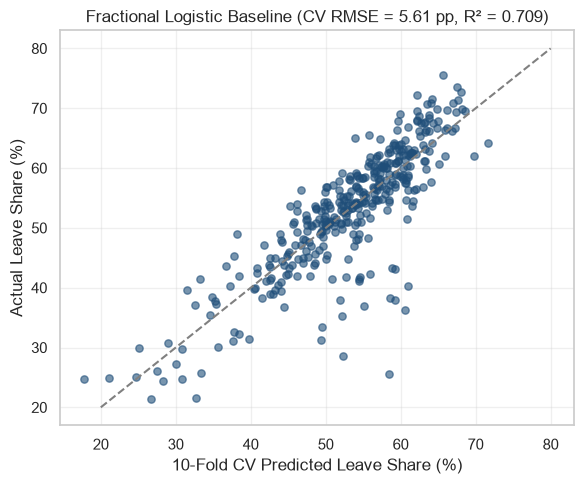

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(cv_pred * 100, y * 100, alpha=0.6, s=28, color="#1f4e79")
ax.plot([20, 80], [20, 80], "--", color="gray")
ax.set_xlabel("10-Fold CV Predicted Leave Share (%)")
ax.set_ylabel("Actual Leave Share (%)")
ax.set_title(f"Fractional Logistic Baseline (CV RMSE = {cv_rmse_pp:.2f} pp, R² = {cv_r2:.3f})")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Simple Fractional Logistic S-Curve Diagram

Each district gets a linear log-odds score $\eta_i = \hat{\beta}_0 + X_i\hat{\beta}$, and the sigmoid curve $\sigma(\eta) = \frac{1}{1 + e^{-\eta}}$ maps it smoothly onto the actual Leave vote proportion $p_i \in (0, 1)$.

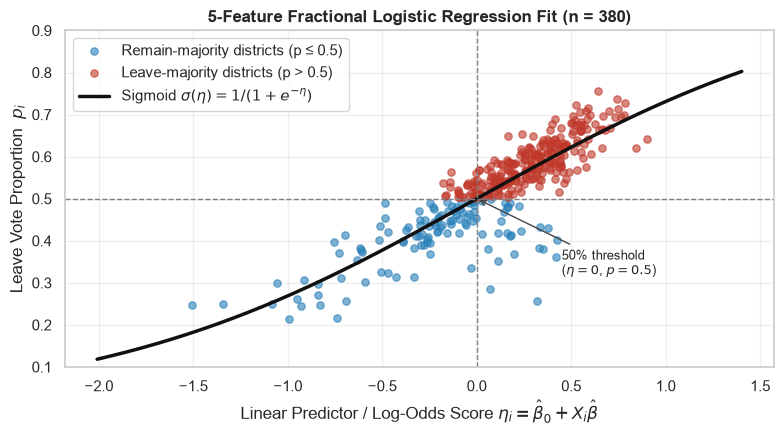

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# Linear predictor (log-odds score) for each of the 380 districts
eta = X @ flogit.params
eta_grid = np.linspace(eta.min() - 0.5, eta.max() + 0.5, 300)
prob_curve = 1 / (1 + np.exp(-eta_grid))

fig, ax = plt.subplots(figsize=(8, 4.5))
remain_mask = y <= 0.5
ax.scatter(eta[remain_mask], y[remain_mask], color="#2980b9", alpha=0.6, s=28, label="Remain-majority districts (p ≤ 0.5)")
ax.scatter(eta[~remain_mask], y[~remain_mask], color="#c0392b", alpha=0.6, s=28, label="Leave-majority districts (p > 0.5)")
ax.plot(eta_grid, prob_curve, color="#111111", linewidth=2.5, label=r"Sigmoid $\sigma(\eta) = 1 / (1 + e^{-\eta})$")

ax.axvline(0, color="gray", linestyle="--", linewidth=1)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.annotate("50% threshold\n($\\eta = 0$, $p = 0.5$)", xy=(0, 0.5), xytext=(0.45, 0.32),
            arrowprops=dict(arrowstyle="->", color="#444"), fontsize=9.5)

ax.set_xlabel(r"Linear Predictor / Log-Odds Score $\eta_i = \hat{\beta}_0 + X_i\hat{\beta}$")
ax.set_ylabel("Leave Vote Proportion  $p_i$")
ax.set_title("5-Feature Fractional Logistic Regression Fit (n = 380)", fontweight="bold")
ax.set_ylim(0.1, 0.9)
ax.legend(loc="upper left", frameon=True)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()